In [1]:
#Import packages
#---------------------------------------
import sys
import os
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import matplotlib
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import glob
import admin_functions as adfn
import trace_analyse as tfn
from tqdm import tqdm
import re
import icg_functions as fn

In [2]:
"""Linear-network scaling, organised for reading and running in notebook cells.

MODEL: x[t+1] = W x[t] + noise[t], W = m A / rho(A), noise covariance Q = I.
A is symmetric and binary. m < 1 gives stationary dynamics; m = 1 is the boundary.
We calculate covariance analytically, sum correlated neuron pairs, then fit
variance ~ K**alpha and integrated timescale ~ K**beta.

This preserves the RECONSTRUCTED calculation, not the unverified historical table.
Default fits use K = 2, 4, 8, 16, 32, 64. Changing this range changes the result.
Run definitions first, then the numbered execution cells at the bottom.
Dependencies: numpy, scipy, pandas, matplotlib.
"""
import os
# For repeatability, set before NumPy is imported; restart an existing kernel first.
for variable in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "OMP_NUM_THREADS"):
    os.environ[variable] = "1"

import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt




In [3]:
def sample_edges(probability, rng):
    """Sample independent upper-triangle edges, reflect them, omit self-loops."""
    n = len(probability)
    upper = np.triu(rng.random((n, n)) < probability, 1)
    return (upper | upper.T).astype(float)


def make_network(n, family, parameter, seed):
    """Return a symmetric n-by-n binary adjacency matrix.

    hm:   parameter=phi; siblings at level ell connect with p=phi**(-ell).
          ell=0 joins pairs, ell=1 joins pairs into fours, etc.
    er:   parameter=expected degree; p=degree/(n-1).
    ring: parameter=even degree k; connect k/2 neighbours on each side.
    sw:   parameter=rewiring probability; rewire an initial k=4 ring.
    sf:   parameter=gamma; Chung-Lu rank weights, mean expected degree 6.

    These graph recipes are reconstruction choices. Random draw order is kept
    fixed; reset the RNG per graph and reuse each graph throughout its m sweep.
    Rings are deterministic: different seeds do not create independent rings.
    """
    rng = np.random.default_rng(seed)
    if family == "hm":
        if parameter < 1:
            raise ValueError("Hierarchical phi must be >= 1.")
        # Highest differing binary digit identifies the sibling-module level.
        labels = np.arange(n)
        xor = labels[:, None] ^ labels[None, :]
        level = np.floor(np.log2(np.maximum(xor, 1))).astype(int)
        return sample_edges(parameter ** (-level.astype(float)), rng)
    if family == "er":
        if not 0 < parameter <= n - 1:
            raise ValueError("ER expected degree must be in (0, n-1].")
        return sample_edges(np.full((n, n), parameter / (n - 1)), rng)
    if family == "sf":
        if parameter <= 1:
            raise ValueError("Scale-free gamma must exceed 1.")
        weights = np.arange(1, n + 1, dtype=float) ** (-1 / (parameter - 1))
        weights *= 6 / weights.mean()
        # Clipping and excluding self-loops can lower actual mean degree.
        probability = np.minimum(np.outer(weights, weights) / weights.sum(), 1)
        return sample_edges(probability, rng)
    if family not in ("ring", "sw"):
        raise ValueError(f"Unknown network family: {family}")

    k = int(parameter) if family == "ring" else 4
    p = 0 if family == "ring" else parameter
    if k < 2 or k >= n or k % 2 or (family == "ring" and k != parameter):
        raise ValueError("Ring degree must be an even integer in [2, n).")
    if not 0 <= p <= 1:
        raise ValueError("Rewiring probability must be in [0, 1].")
    adjacency = np.zeros((n, n))
    for offset in range(1, k // 2 + 1):
        for i in range(n):
            j = (i + offset) % n
            adjacency[i, j] = adjacency[j, i] = 1
    if p:
        for offset in range(1, k // 2 + 1):
            for i in range(n):
                j = (i + offset) % n
                if rng.random() < p:
                    candidates = np.flatnonzero((adjacency[i] == 0) & (np.arange(n) != i))
                    if candidates.size:
                        other = rng.choice(candidates)
                        adjacency[i, j] = adjacency[j, i] = 0
                        adjacency[i, other] = adjacency[other, i] = 1
    return adjacency




In [4]:

def stationary_covariances(eigenvalues, eigenvectors, m):
    """Return S = Cov(x) and L = sum_{lag=0}^infinity W**lag S.

    With symmetric W and Q=I, eigenmodes are independent AR(1) processes:
        lambda = m * eigenvalue(A) / rho(A)
        modal variance = 1 / (1 - lambda**2)
        modal integrated covariance = variance / (1 - lambda)
    No activity simulation or numerical autocorrelation fitting is needed.
    """
    if not 0 <= m < 1:
        raise ValueError("Stationarity requires 0 <= m < 1.")
    radius = np.max(np.abs(eigenvalues))
    if radius == 0:
        raise ValueError("Cannot normalise an empty network.")
    lam = m * eigenvalues / radius
    variance = 1 / ((1 - lam) * (1 + lam))
    S = (eigenvectors * variance) @ eigenvectors.T
    L = (eigenvectors * (variance / (1 - lam))) @ eigenvectors.T
    return S, L




In [5]:

def greedy_pairs(S):
    """Pair next unused index with its highest-correlated unused partner.

    This is index-order greedy pairing, not a global maximum-matching algorithm.
    Raw float64 argmax preserves the reconstruction. Nearly tied correlations
    can resolve differently across BLAS/LAPACK versions, especially in rings.
    """
    sd = np.sqrt(np.diag(S))
    correlation = S / np.outer(sd, sd)
    np.fill_diagonal(correlation, -np.inf)
    available = np.ones(len(S), dtype=bool)
    pairs = []
    for i in range(len(S)):
        if not available[i]:
            continue
        available[i] = False
        j = int(np.argmax(np.where(available, correlation[i], -np.inf)))
        if not available[j]:
            raise ValueError("Pairing requires an even number of clusters.")
        available[j] = False
        pairs.append((i, j))
    return np.asarray(pairs)


def pool(matrix, pairs):
    """Covariance of pair SUMS: equivalent to P @ matrix @ P.T."""
    a, b = pairs.T
    return (matrix[np.ix_(a, a)] + matrix[np.ix_(a, b)]
            + matrix[np.ix_(b, a)] + matrix[np.ix_(b, b)])


def coarse_grain(S, L, min_clusters=4):
    """Return variance and timescale at each cluster size K.

    variance = mean cluster-sum variance.
    tau = trace(L)/trace(S): variance-weighted integrated autocorrelation,
    including lag zero, measured in time steps. It is NOT an exponential-fit tau.
    For N=512, min_clusters=4 records K=1,2,...,128.
    """
    records, K = [], 1
    while len(S) >= min_clusters:
        records.append({"K": K, "clusters": len(S),
                        "variance": np.trace(S) / len(S),
                        "tau": np.trace(L) / np.trace(S)})
        if len(S) == 1:
            break
        pairs = greedy_pairs(S)
        S, L = pool(S, pairs), pool(L, pairs)
        K *= 2
    return pd.DataFrame(records)


def fit_scaling(levels, drop_first=1, drop_last=1):
    """OLS log-log slopes and R-squared; drop endpoints before fitting.

    Defaults fit K=2..64 for N=512 and min_clusters=4. A slope alone does not
    establish a power law: inspect the level curves and R-squared as well.
    """
    end = len(levels) - drop_last if drop_last else len(levels)
    fitted = levels.iloc[drop_first:end]
    if len(fitted) < 2:
        raise ValueError("At least two coarse-graining levels must remain.")
    result = {}
    x = np.log(fitted.K.to_numpy())
    for column, exponent in (("variance", "alpha"), ("tau", "beta")):
        y = np.log(fitted[column].to_numpy())
        slope, intercept = np.polyfit(x, y, 1)
        residual = np.sum((y - (intercept + slope * x)) ** 2)
        total = np.sum((y - y.mean()) ** 2)
        result[exponent] = float(slope)
        result[exponent + "_r2"] = float(1 - residual / total) if total > 1e-20 else np.nan
    return result




In [6]:

def run_sweep(n, networks, seeds, m_values, min_clusters=4, drop_first=1, drop_last=1):
    """Return per-seed exponents, all scale-level measurements and adjacency matrices.

    Compute each graph's eigendecomposition once; reuse it for every m.
    No files are written here, and no historical results enter the calculations.
    """
    if n < 16 or n & (n - 1):
        raise ValueError("n must be a power of two >= 16.")
    if min_clusters not in (1, 2, 4, 8) or min_clusters > n:
        raise ValueError("min_clusters must be 1, 2, 4 or 8, and <= n.")
    if drop_first < 0 or drop_last < 0:
        raise ValueError("Endpoint counts must be nonnegative.")
    rows, curves, graphs = [], [], {}
    for name, family, parameter in networks:
        for seed in seeds:
            A = make_network(n, family, parameter, seed)
            eigenvalues, eigenvectors = eigh(A, check_finite=False)
            graphs[f"{name}_seed{seed}"] = A.astype(np.uint8)
            for m in m_values:
                S, L = stationary_covariances(eigenvalues, eigenvectors, m)
                levels = coarse_grain(S, L, min_clusters)
                metadata = {"network": name, "seed": seed, "m": m}
                rows.append({**metadata, **fit_scaling(levels, drop_first, drop_last)})
                curves.append(levels.assign(**metadata))
            print(f"Completed {name}, seed {seed}", flush=True)
    return pd.DataFrame(rows), pd.concat(curves, ignore_index=True), graphs


def summarise(exponents, target=(1.5, 0.2), beta_weight=2):
    """Select best m using distance of SEED-MEAN exponents to the target.

    distance = sqrt((mean_alpha-target_alpha)^2
                    + beta_weight^2 * (mean_beta-target_beta)^2).
    Two seeds give weak uncertainty estimates; ring seeds are identical graphs.
    """
    summary = exponents.groupby(["network", "m"], sort=False).agg(
        alpha_mean=("alpha", "mean"), beta_mean=("beta", "mean"),
        alpha_sem=("alpha", "sem"), beta_sem=("beta", "sem"),
        alpha_r2_mean=("alpha_r2", "mean"), beta_r2_mean=("beta_r2", "mean"),
    ).reset_index()
    summary["distance"] = np.hypot(summary.alpha_mean - target[0],
                                   beta_weight * (summary.beta_mean - target[1]))
    best = summary.loc[summary.groupby("network", sort=False).distance.idxmin()].reset_index(drop=True)
    return summary, best




In [11]:
N = 512
SEEDS = [7, 8]
M_VALUES = (
    1 - np.geomspace(1 - 0.50, 1 - 0.999999, 150)
).tolist()
NETWORKS = [
    ("HM_phi2.25", "hm", 2.25), ("HM_phi2.83", "hm", 2.83),
    ("HM_phi3.50", "hm", 3.50), ("ER_k3.3", "er", 3.3),
    ("ER_k6.2", "er", 6.2), ("Ring_k4", "ring", 4),
    ("Ring_k6", "ring", 6), ("SW_p0.01", "sw", .01),
    ("SW_p0.1", "sw", .1), ("SF_gamma2.1", "sf", 2.1),
    ("SF_gamma3.0", "sf", 3.0),
]
MIN_CLUSTERS = 4   # Stop recording when fewer clusters remain.
DROP_FIRST = 1     # Exclude K=1.
DROP_LAST = 1      # Exclude K=128: default fit is K=2..64.
TARGET = (1.5, 0.2)
BETA_WEIGHT = 2
SAVE = False      # Set True to write tables, graphs, settings and figure in cell E.
OUTDIR = Path("linear_scaling_results")




In [12]:
exponents, levels, graphs = run_sweep(
    N, NETWORKS, SEEDS, M_VALUES, MIN_CLUSTERS, DROP_FIRST, DROP_LAST
)
summary, best = summarise(exponents, TARGET, BETA_WEIGHT)
print(f"\nCompleted {len(exponents)} evaluations.")


Completed HM_phi2.25, seed 7
Completed HM_phi2.25, seed 8
Completed HM_phi2.83, seed 7
Completed HM_phi2.83, seed 8
Completed HM_phi3.50, seed 7
Completed HM_phi3.50, seed 8
Completed ER_k3.3, seed 7
Completed ER_k3.3, seed 8
Completed ER_k6.2, seed 7
Completed ER_k6.2, seed 8
Completed Ring_k4, seed 7
Completed Ring_k4, seed 8
Completed Ring_k6, seed 7
Completed Ring_k6, seed 8
Completed SW_p0.01, seed 7
Completed SW_p0.01, seed 8
Completed SW_p0.1, seed 7
Completed SW_p0.1, seed 8
Completed SF_gamma2.1, seed 7
Completed SF_gamma2.1, seed 8
Completed SF_gamma3.0, seed 7
Completed SF_gamma3.0, seed 8

Completed 3300 evaluations.


In [13]:
columns = ["network", "m", "alpha_mean", "beta_mean", "distance",
           "alpha_r2_mean", "beta_r2_mean"]
print(best[columns].round(6).to_string(index=False))
# Full per-seed results: exponents. Full coarse-graining curves: levels.
# All m values, including SEM: summary. Best m for each network: best.




    network        m  alpha_mean  beta_mean  distance  alpha_r2_mean  beta_r2_mean
 HM_phi2.25 0.997678    1.734186   0.257474  0.260876       0.997733      0.913168
 HM_phi2.83 0.998747    1.627426   0.223172  0.135592       0.998285      0.974281
 HM_phi3.50 0.998852    1.518980   0.202871  0.019830       0.997652      0.920403
    ER_k3.3 0.998053    1.700647   0.259427  0.233208       0.997728      0.924498
    ER_k6.2 0.997678    1.741149   0.252082  0.262684       0.997616      0.903868
    Ring_k4 0.974966    1.505316   0.213689  0.027889       0.995388      0.984909
    Ring_k6 0.970144    1.530263   0.236037  0.078170       0.996915      0.984055
   SW_p0.01 0.986486    1.514090   0.224048  0.050118       0.996071      0.994038
    SW_p0.1 0.998217    1.686224   0.258497  0.219925       0.999859      0.992995
SF_gamma2.1 0.996976    1.662233   0.247911  0.188418       0.998829      0.900586
SF_gamma3.0 0.997231    1.670738   0.245525  0.193499       0.998546      0.902726


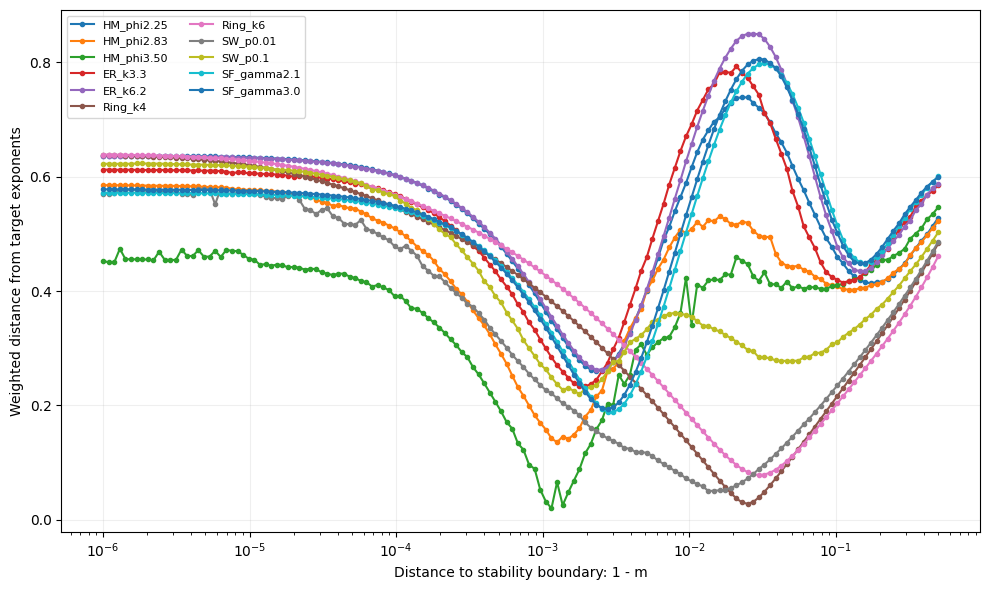

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
for name, curve in summary.groupby("network", sort=False):
    ax.plot(1 - curve.m, curve.distance, "o-", markersize=3, label=name)
ax.set(xscale="log", xlabel="Distance to stability boundary: 1 - m",
       ylabel="Weighted distance from target exponents")
ax.grid(alpha=.2)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()
# Only m<1 was tested: this does not compare with stationary supercritical dynamics.